In [2]:
import pandas as pd

df = pd.read_csv("advertising_sales.csv")

In [3]:
print(df.head(5))

   TV_Advertising_Budget  Sales
0                     10    8.5
1                     15    9.8
2                     20   12.1
3                     25   13.0
4                     30   15.2


In [4]:
print(df.tail(5))

    TV_Advertising_Budget  Sales
25                    135   45.0
26                    140   47.2
27                    145   48.1
28                    150   49.5
29                    160   53.8


In [5]:
print(df.describe())

       TV_Advertising_Budget      Sales
count              30.000000  30.000000
mean               82.666667  30.230000
std                44.309517  12.958319
min                10.000000   8.500000
25%                46.250000  19.575000
50%                82.500000  30.250000
75%               118.750000  40.775000
max               160.000000  53.800000


In [6]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 2 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   TV_Advertising_Budget  30 non-null     int64  
 1   Sales                  30 non-null     float64
dtypes: float64(1), int64(1)
memory usage: 612.0 bytes
None


In [ ]:
print(df.duplicated().sum())
print(df.isnull().sum())

0
TV_Advertising_Budget    0
Sales                    0
dtype: int64


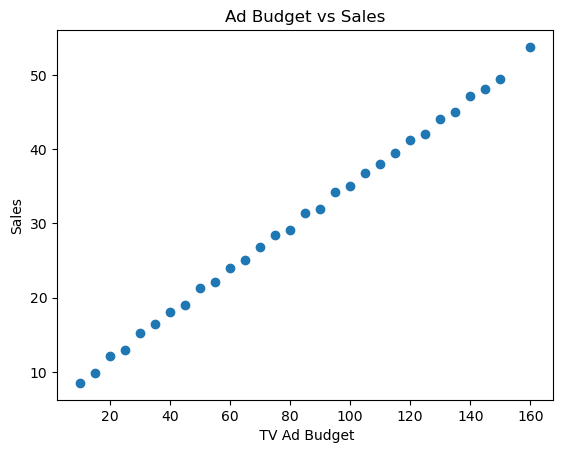

In [8]:
import matplotlib.pyplot as plt

plt.scatter(df['TV_Advertising_Budget'],df['Sales'])

plt.title("Ad Budget vs Sales")
plt.xlabel(" TV Ad Budget")
plt.ylabel("Sales")
plt.show()

In [9]:
X = df[['TV_Advertising_Budget']]
y = df['Sales']

In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,y,
                                                    random_state= 42, test_size=0.2)

In [11]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [12]:
y_pred = model.predict(X_test)
print(y_pred)

[48.50955067 30.89813397 42.63907844 33.83337009 20.62480757 22.09242562]


In [13]:
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score
import numpy as np

print("MAE",mean_absolute_error(y_test,y_pred))
print("MSE",mean_squared_error(y_test,y_pred))
rmse = np.sqrt(mean_squared_error(y_test,y_pred))
print("RMSE",rmse)
print("R2 Score",r2_score(y_test,y_pred))

MAE 0.4333153092022008
MSE 0.23639703248412972
RMSE 0.4862067795538537
R2 Score 0.9975050810837048


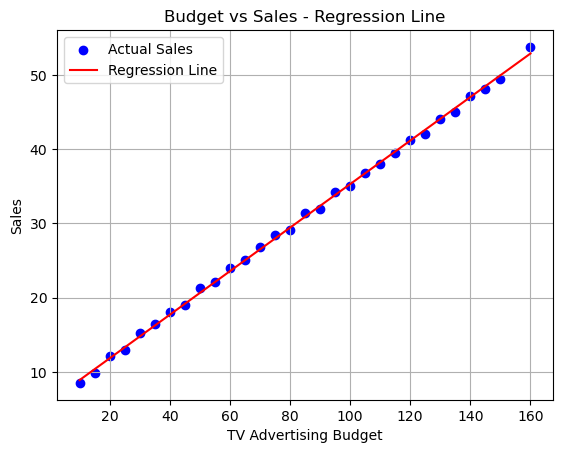

In [14]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Generate predictions
prediction = model.predict(X)

# 2. Get indices to sort advertising budgets
sorted_indices = np.argsort(X['TV_Advertising_Budget'].values)

# 3. Plot actual sales
plt.scatter(X, y, color="blue", label="Actual Sales")

# 4. Plot regression line
plt.plot(
    X['TV_Advertising_Budget'].values[sorted_indices],
    prediction[sorted_indices],
    color="red",
    label="Regression Line"
)

plt.title("Budget vs Sales - Regression Line")
plt.xlabel("TV Advertising Budget")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)
plt.show()

In [17]:
residuals = y_test - y_pred
comparison = pd.DataFrame({
    'Ad_Budget': X_test['TV_Advertising_Budget'],
    'Actual_Sales': y_test,
    'Predicted_Sales': y_pred,
    'Residual': residuals
})

print(comparison)

    Ad_Budget  Actual_Sales  Predicted_Sales  Residual
27        145          48.1        48.509551 -0.409551
15         85          31.4        30.898134  0.501866
23        125          42.0        42.639078 -0.639078
17         95          34.2        33.833370  0.366630
8          50          21.3        20.624808  0.675192
9          55          22.1        22.092426  0.007574


Checking - Homoscedasticty

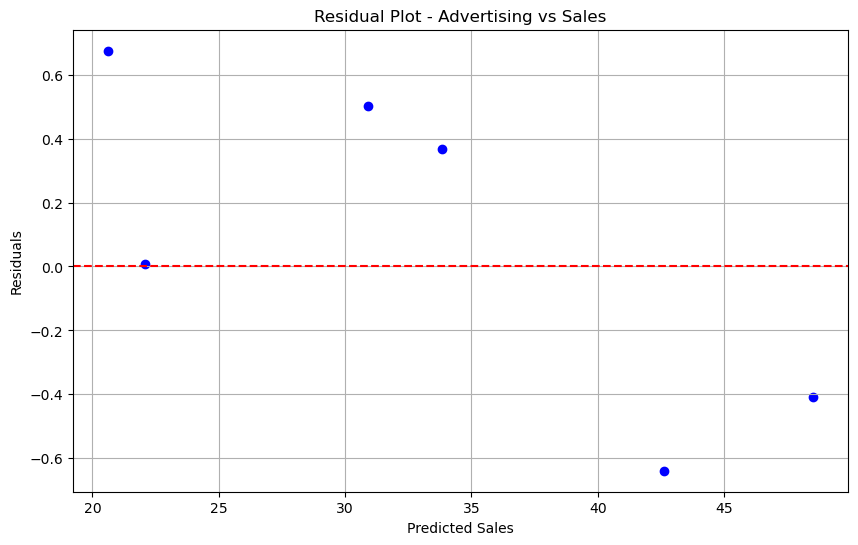

In [19]:

plt.figure(figsize=(10, 6))

plt.scatter(y_pred, residuals, color='blue')

plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel('Predicted Sales')
plt.ylabel('Residuals')
plt.title('Residual Plot - Advertising vs Sales')

plt.grid(True)
plt.show()

Positive residuals: Four points are above zero. Your model underpredicted sales for those observations.



Negative residuals: Two points are below zero. Your model overpredicted sales for those observations.



Near-zero residual: One point is almost exactly on the zero line. The prediction was very close to the actual sales.

Points above zero: Positive residuals (underprediction).



Points below zero: Negative residuals (overprediction).



Points close to zero: Accurate predictions.

our residuals appear to show a pattern:
- At lower predicted sales (around 21–34), residuals are mostly positive.
- At higher predicted sales (around 42–48), residuals are negative.
This suggests your model tends to:
- Underpredict at lower sales values.
- Overpredict at higher sales values.
That could indicate the relationship is not perfectly linear.

However, your test set appears to contain only seven observations, so we shouldn't draw a strong conclusion from this pattern alone.

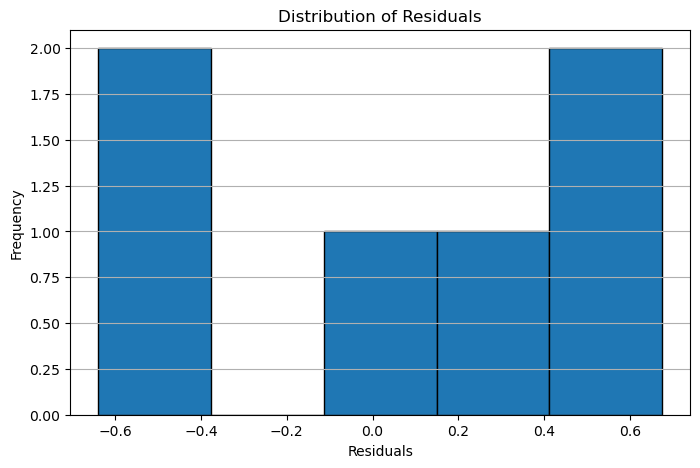

In [21]:
plt.figure(figsize=(8, 5))

plt.hist(residuals, bins=5, edgecolor='black')

plt.title("Distribution of Residuals")
plt.xlabel("Residuals")
plt.ylabel("Frequency")

plt.grid(axis='y')
plt.show()

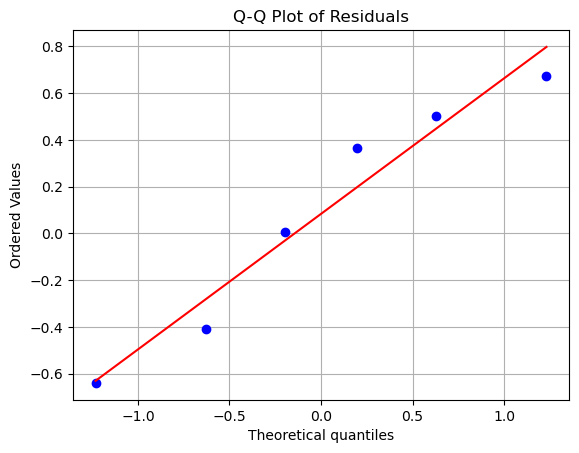

In [24]:
import scipy.stats as stats

stats.probplot(residuals, dist="norm", plot=plt)

plt.title("Q-Q Plot of Residuals")
plt.grid()
plt.show()